# Módulo 04 · Reshape: `pivot_table`, `melt`, `stack`/`unstack`, `crosstab`, `explode`

**Curso de pandas intermedio → avanzado** · Dataset: *Olist* (muestras en `data/`)

## Objetivos
1. Distinguir datos **largos** (*tidy*) y **anchos**, y saber cuándo conviene cada uno.
2. Pasar de largo a ancho con `pivot` y `pivot_table` (agregación, `fill_value`, `margins`).
3. Pasar de ancho a largo con `melt`.
4. Mover niveles entre filas y columnas con `stack` / `unstack` (y el cambio de pandas 3).
5. Construir tablas de contingencia con `crosstab` y normalizarlas.
6. Desanidar listas con `explode` y crear variables indicadoras con `get_dummies`.

| Sección | Tema |
|---|---|
| 0 | Setup y carga |
| 1 | Largo vs ancho |
| 2 | `pivot` y `pivot_table` |
| 3 | `melt` |
| 4 | `stack` / `unstack` |
| 5 | `crosstab` |
| 6 | `explode` |
| 7 | `get_dummies` y `from_dummies` |
| ✍️ | Ejercicios · ✅ Soluciones |

## 0 · Setup y carga

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA = Path("data")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)


def pendiente(*valores) -> bool:
  # True si algún valor sigue siendo `...` (ejercicio sin resolver)
  return any(v is ... for v in valores)


print("pandas", pd.__version__)

pandas 3.1.1


In [2]:
orders = pd.read_csv(
  DATA / "olist_orders_dataset.csv",
  usecols=["order_id", "customer_id", "order_status", "order_purchase_timestamp",
           "order_delivered_customer_date", "order_estimated_delivery_date"],
  dtype={"order_status": "category"},
  parse_dates=["order_purchase_timestamp", "order_delivered_customer_date",
               "order_estimated_delivery_date"],
)

payments = pd.read_csv(
  DATA / "olist_order_payments_dataset.csv",
  dtype={"payment_type": "category", "payment_sequential": "int8",
         "payment_installments": "int8"},
)

reviews = pd.read_csv(
  DATA / "olist_order_reviews_dataset.csv",
  usecols=["review_id", "order_id", "review_score", "review_comment_message"],
  dtype={"review_score": pd.CategoricalDtype([1, 2, 3, 4, 5], ordered=True)},
)

products = pd.read_csv(
  DATA / "olist_products_dataset.csv",
  usecols=["product_id", "product_category_name", "product_weight_g",
           "product_length_cm", "product_height_cm", "product_width_cm"],
)

customers = pd.read_csv(
  DATA / "olist_customers_dataset.csv",
  usecols=["customer_id", "customer_state"],
  dtype={"customer_state": "category"},
)

Una tabla base que usaremos en varias secciones: cada pago con su estado y mes de compra.

In [3]:
pagos = (
  payments
  .merge(orders[["order_id", "customer_id", "order_purchase_timestamp"]], on="order_id")
  .merge(customers, on="customer_id")
  .assign(mes=lambda d: d["order_purchase_timestamp"].dt.to_period("M"))
  .drop(columns=["customer_id", "order_purchase_timestamp"])
)
pagos.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value,customer_state,mes
0,243312dbb316253ab77bb0140d94803c,1,credit_card,10,285.79,SP,2018-03
1,92f4f749aa508d58dee50d9ccdb6c9dd,1,credit_card,3,62.31,GO,2018-07
2,f75517cfb973c21eab8559a870263794,1,credit_card,10,231.27,MG,2017-07
3,56430e0b9968b381942760e433583b27,1,debit_card,1,33.10,RJ,2017-03
4,8ef3801f58da6b652a3082e1fa5b6589,1,credit_card,2,129.15,SP,2018-03


## 1 · Largo vs ancho

| Formato | Forma | Bueno para |
|---|---|---|
| **Largo** (*tidy*) | una fila por observación; las "variables" son valores de una columna | `groupby`, filtros, gráficos con seaborn, guardar datos |
| **Ancho** | una fila por entidad; cada variable es una columna | reportes, comparar lado a lado, matrices, modelos |

El mismo dato en ambas formas:

In [4]:
largo = pagos.groupby(["customer_state", "payment_type"], observed=True, as_index=False)["payment_value"].sum()
largo.head(6)

,customer_state,payment_type,payment_value
0,AC,boleto,158.27
1,AL,credit_card,162.29
2,BA,boleto,196.29
3,BA,credit_card,1761.85
4,BA,voucher,50.00
5,CE,boleto,197.54


In [5]:
ancho = largo.pivot(index="customer_state", columns="payment_type", values="payment_value")
ancho.head()

payment_type,boleto,credit_card,debit_card,voucher
customer_state,,,,
AC,158.27,NaN,NaN,NaN
AL,NaN,162.29,NaN,NaN
BA,196.29,1761.85,NaN,50.0
CE,197.54,244.27,NaN,NaN
DF,351.58,735.32,NaN,NaN


Regla práctica: **calcula en largo, presenta en ancho.** Las funciones de este módulo son el puente entre ambas.

```
          pivot / pivot_table / unstack
  LARGO  ───────────────────────────────▶  ANCHO
         ◀───────────────────────────────
               melt / stack
```

## 2 · `pivot` y `pivot_table`

### `pivot`: sólo reorganiza

`pivot` **no agrega**. Si una combinación `(index, columns)` aparece más de una vez, falla:

In [6]:
try:
  pagos.pivot(index="customer_state", columns="payment_type", values="payment_value")
except ValueError as e:
  print("ValueError:", e)

ValueError: Index contains duplicate entries, cannot reshape


### `pivot_table`: agrega y reorganiza

Es un `groupby` + `unstack` en una sola llamada.

| Parámetro | Para qué |
|---|---|
| `index`, `columns`, `values` | llaves de filas, de columnas y columna(s) a agregar |
| `aggfunc` | función o lista/dict (default **`"mean"`** ⚠️) |
| `fill_value` | reemplazar celdas vacías |
| `margins=True` | totales de filas y columnas (`margins_name`) |
| `observed` | con `category`, sólo combinaciones existentes (default `True`) |

In [7]:
pt = pagos.pivot_table(
  index="customer_state",
  columns="payment_type",
  values="payment_value",
  aggfunc="sum",
  fill_value=0,
  margins=True,
  margins_name="Total",
)
pt.sort_values("Total", ascending=False).round(0).head(8)

payment_type,boleto,credit_card,debit_card,voucher,Total
customer_state,,,,,
Total,5766.0,36768.0,99.0,508.0,43140.0
SP,1695.0,13741.0,66.0,191.0,15692.0
RJ,1335.0,5431.0,33.0,72.0,6871.0
MG,675.0,5441.0,0.0,150.0,6267.0
RS,198.0,2489.0,0.0,0.0,2687.0
BA,196.0,1762.0,0.0,50.0,2008.0
PR,611.0,1316.0,0.0,0.0,1927.0
PE,0.0,1467.0,0.0,44.0,1511.0


> ⚠️ El `aggfunc` por defecto es **`"mean"`**. Olvidar `aggfunc="sum"` es uno de los errores más comunes en reportes.

Varias medidas y funciones a la vez (columnas `MultiIndex`):

In [8]:
pagos.pivot_table(
  index="payment_type",
  values=["payment_value", "payment_installments"],
  aggfunc={"payment_value": ["sum", "mean"], "payment_installments": "median"},
).round(2)

payment_installments payment_value          
                           median          mean       sum
payment_type                                             
boleto                        1.0        106.78   5766.31
credit_card                   3.0        152.56  36767.90
debit_card                    1.0         32.88     98.65
voucher                       1.0         46.14    507.55

Con el tiempo en las filas: una matriz mes × método lista para graficar.

In [9]:
mensual = pagos.pivot_table(index="mes", columns="payment_type", values="payment_value",
                            aggfunc="sum", fill_value=0)
mensual.tail()

payment_type,boleto,credit_card,debit_card,voucher
mes,,,,
2018-04,237.99,4332.18,0.0,0.00
2018-05,461.59,3545.10,0.0,0.00
2018-06,400.40,3366.68,0.0,0.00
2018-07,358.46,1261.95,0.0,73.89
2018-08,313.58,2686.01,0.0,148.09


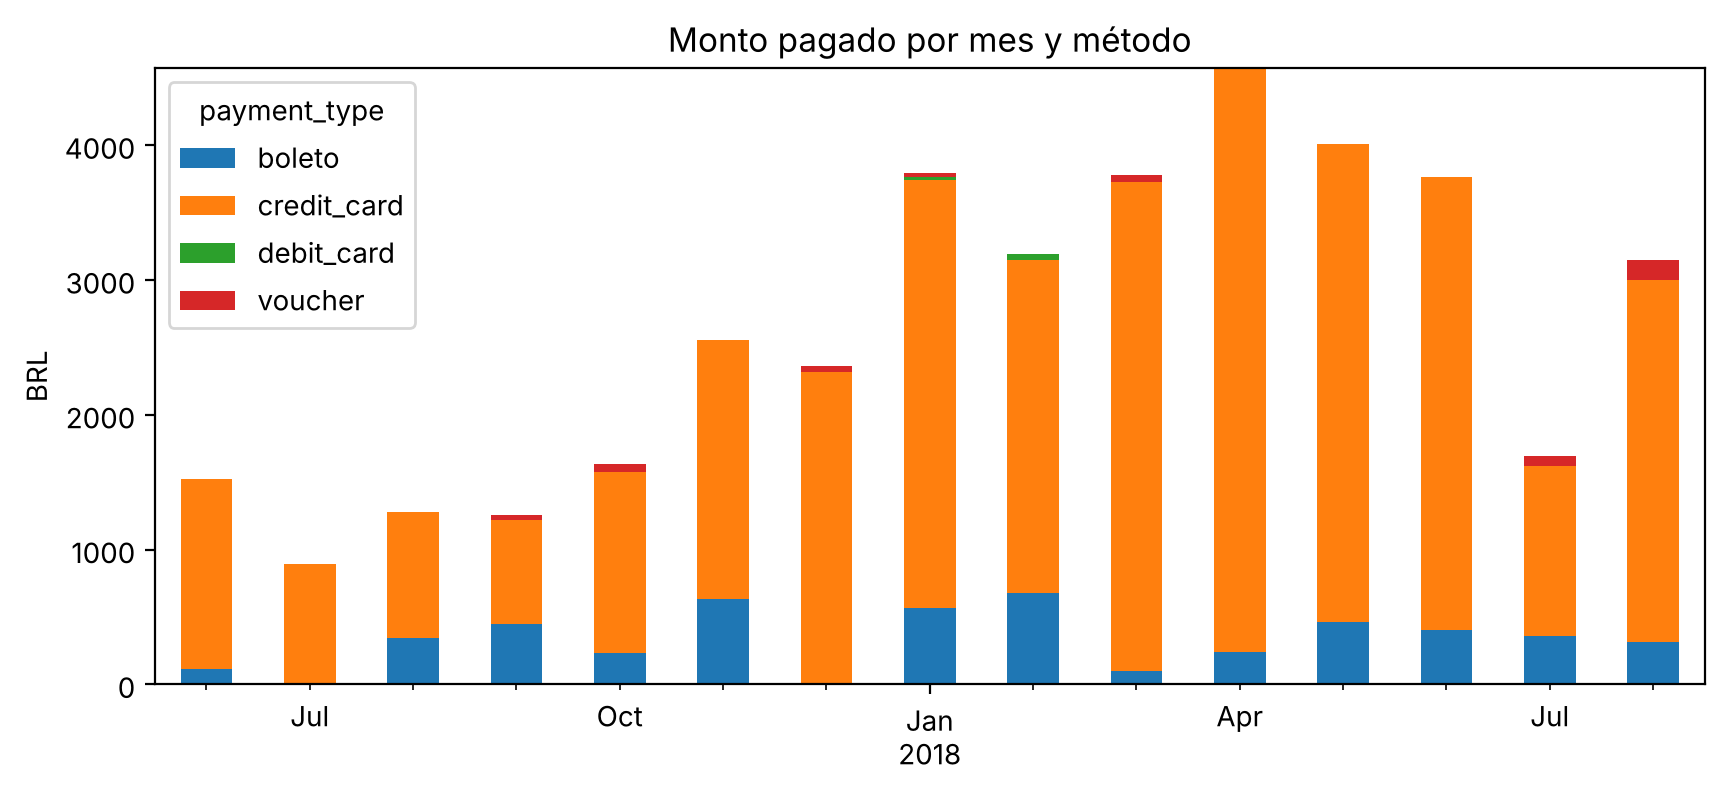

In [10]:
ax = mensual.loc["2017-06":].plot(kind="bar", stacked=True, figsize=(10, 4),
                                   title="Monto pagado por mes y método")
ax.set_xlabel(""); ax.set_ylabel("BRL");

## 3 · `melt`

`melt` "derrite" columnas en filas: de ancho a largo.

| Parámetro | Para qué |
|---|---|
| `id_vars` | columnas que identifican cada fila (se repiten) |
| `value_vars` | columnas a convertir en filas (default: todas las demás) |
| `var_name` / `value_name` | nombres de las nuevas columnas |
| `ignore_index` | `False` conserva el índice original |

In [11]:
dims = products[["product_id", "product_length_cm", "product_height_cm", "product_width_cm"]]
dims.head(3)

,product_id,product_length_cm,product_height_cm,product_width_cm
0,c6336fa91fbd87c359e44f5dca5a90ed,16.0,16.0,11.0
1,00a985c524adbb97a4211e4ce17aabec,17.0,4.0,12.0
2,3932e37f1f658768ac53fbe680f145bc,40.0,10.0,30.0


In [12]:
dims_largo = dims.melt(
  id_vars="product_id",
  var_name="dimension",
  value_name="cm",
)
dims_largo["dimension"] = dims_largo["dimension"].str.removeprefix("product_").str.removesuffix("_cm")
dims_largo.sort_values("product_id").head(6)

,product_id,dimension,cm
1,00a985c524adbb97a4211e4ce17aabec,length,17.0
297,00a985c524adbb97a4211e4ce17aabec,height,4.0
593,00a985c524adbb97a4211e4ce17aabec,width,12.0
276,016711f78a6a87696645db0a6a834826,length,27.0
572,016711f78a6a87696645db0a6a834826,height,22.0
868,016711f78a6a87696645db0a6a834826,width,39.0


En largo, preguntas que en ancho requerirían código por columna se vuelven un `groupby`:

In [13]:
dims_largo.groupby("dimension")["cm"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
dimension,,,,,,,,
height,296.0,15.9,14.4,2.0,7.0,12.0,20.0,105.0
length,296.0,29.1,15.1,7.0,17.0,24.0,37.0,104.0
width,296.0,22.3,11.7,9.0,15.0,19.0,30.0,90.0


`melt` es el inverso de `pivot`. Ida y vuelta:

In [14]:
de_vuelta = dims_largo.pivot(index="product_id", columns="dimension", values="cm")
de_vuelta.head(3)

dimension,height,length,width
product_id,,,
00a985c524adbb97a4211e4ce17aabec,4.0,17.0,12.0
016711f78a6a87696645db0a6a834826,22.0,27.0,39.0
02475368dfb38934fe55f574024fe1d7,2.0,16.0,11.0


Un uso clásico: **reportes anchos que llegan de Excel**. `melt` del resultado del `pivot_table` anterior:

In [15]:
mensual.reset_index().melt(id_vars="mes", value_name="monto").query("monto > 0").head()

,mes,payment_type,monto
1,2017-02,boleto,255.81
2,2017-03,boleto,152.29
4,2017-05,boleto,469.33
5,2017-06,boleto,113.62
7,2017-08,boleto,342.07


## 4 · `stack` / `unstack`

Trabajan con **niveles de índice** (no con columnas por nombre):

- `unstack(nivel)`: un nivel del **índice** pasa a **columnas** (largo → ancho).
- `stack(nivel)`: un nivel de **columnas** pasa al **índice** (ancho → largo).

In [16]:
conteo = pagos.groupby(["customer_state", "payment_type"], observed=True).size()
conteo.head(6)

customer_state  payment_type
AC              boleto          1
AL              credit_card     1
BA              boleto          3
                credit_card     8
                voucher         1
CE              boleto          2
dtype: int64

In [17]:
tabla = conteo.unstack("payment_type", fill_value=0)
tabla.head()

payment_type,boleto,credit_card,debit_card,voucher
customer_state,,,,
AC,1,0,0,0
AL,0,1,0,0
BA,3,8,0,1
CE,2,1,0,0
DF,2,3,0,0


In [18]:
tabla.unstack().head()        # ¡unstack de un DataFrame sin MultiIndex en filas devuelve una Series!

payment_type  customer_state
boleto        AC                1
              AL                0
              BA                3
              CE                2
              DF                2
dtype: int64

### Cambio de pandas 3: `stack` ya no descarta `NaN`

En pandas 2, `stack()` eliminaba por defecto las celdas vacías (`dropna=True`). La nueva implementación de pandas 3 **las conserva**. Si quieres el comportamiento anterior, hazlo explícito con `.dropna()`.

In [19]:
ancho_con_nan = largo.pivot(index="customer_state", columns="payment_type", values="payment_value")
apilado = ancho_con_nan.stack()
print("Filas en ancho×columnas:", ancho_con_nan.size)
print("Filas tras stack()      :", len(apilado), "| NaN:", apilado.isna().sum())
print("Filas tras .dropna()    :", len(apilado.dropna()))

Filas en ancho×columnas: 88
Filas tras stack()      : 88 | NaN: 49
Filas tras .dropna()    : 39


### Patrón: normalizar con `unstack` → operar → `stack`

Participación de cada método de pago **dentro de cada estado**:

In [20]:
participacion = (
  tabla.div(tabla.sum(axis=1), axis=0)     # cada fila suma 1
       .mul(100)
       .round(1)
)
participacion.head()

payment_type,boleto,credit_card,debit_card,voucher
customer_state,,,,
AC,100.0,0.0,0.0,0.0
AL,0.0,100.0,0.0,0.0
BA,25.0,66.7,0.0,8.3
CE,66.7,33.3,0.0,0.0
DF,40.0,60.0,0.0,0.0


In [21]:
# De vuelta a largo para filtrar o graficar
participacion.stack().rename("pct").reset_index().query("pct >= 50").head()

,customer_state,payment_type,pct
0,AC,boleto,100.0
5,AL,credit_card,100.0
9,BA,credit_card,66.7
12,CE,boleto,66.7
17,DF,credit_card,60.0


## 5 · `crosstab`

Tablas de **frecuencia** entre dos o más variables categóricas. Trabaja sobre Series (no necesita un DataFrame) y tiene un parámetro clave: `normalize`.

| `normalize` | Cada celda es… |
|---|---|
| `False` | conteo |
| `"index"` | % de su **fila** |
| `"columns"` | % de su **columna** |
| `"all"` | % del total |

In [22]:
pd.crosstab(pagos["customer_state"], pagos["payment_type"], margins=True).tail()

payment_type,boleto,credit_card,debit_card,voucher,All
customer_state,,,,,
SC,3,8,0,0,11
SE,0,1,0,0,1
SP,20,107,2,5,134
TO,1,0,0,0,1
All,54,241,3,11,309


In [23]:
pd.crosstab(pagos["payment_type"], pagos["payment_installments"] > 1,
            normalize="index").mul(100).round(1).rename(columns={False: "1 cuota", True: "a plazos"})

payment_installments,1 cuota,a plazos
payment_type,,
boleto,100.0,0.0
credit_card,34.0,66.0
debit_card,100.0,0.0
voucher,100.0,0.0


`crosstab` también agrega valores con `values` + `aggfunc` (equivalente a un `pivot_table`):

In [24]:
pd.crosstab(pagos["customer_state"], pagos["payment_type"],
            values=pagos["payment_value"], aggfunc="mean").round(1).head()

payment_type,boleto,credit_card,debit_card,voucher
customer_state,,,,
AC,158.3,NaN,NaN,NaN
AL,NaN,162.3,NaN,NaN
BA,65.4,220.2,NaN,50.0
CE,98.8,244.3,NaN,NaN
DF,175.8,245.1,NaN,NaN


## 6 · `explode`

`explode` convierte cada elemento de una **lista** en su propia fila, repitiendo el resto de columnas. Muy útil con texto, etiquetas, JSON o el resultado de `agg(list)`.

In [25]:
tipos_por_pedido = (
  payments.groupby("order_id")["payment_type"]
  .agg(lambda s: sorted(s.astype(str).unique()))
  .rename("metodos")
)
tipos_por_pedido[tipos_por_pedido.str.len() > 1].head()

order_id
042649285cd08ef7c546445419b43407    [credit_card, voucher]
09fd9b0402ed675bbd1ee1e81171ac7c    [credit_card, voucher]
3a73a24fa6a0d8ffd462fb4bb62e66fc    [credit_card, voucher]
636f0241ddc83a3b9e37a8088167bd45    [credit_card, voucher]
c6c96aae858cf470816e5080de363e47    [credit_card, voucher]
Name: metodos, dtype: object

In [26]:
tipos_por_pedido.explode().value_counts()

metodos
credit_card    240
boleto          54
voucher         11
debit_card       3
Name: count, dtype: int64

### Texto: palabras de las reseñas

In [27]:
palabras = (
  reviews.dropna(subset=["review_comment_message"])
  .assign(palabra=lambda d: d["review_comment_message"]
                            .str.lower()
                            .str.replace(r"[^\w\s]", " ", regex=True)
                            .str.split())
  .explode("palabra", ignore_index=True)
)
palabras[["review_id", "review_score", "palabra"]].head(8)

,review_id,review_score,palabra
0,30f2619843ddd4a19bbcb306669d2bf0,5,só
1,30f2619843ddd4a19bbcb306669d2bf0,5,imaginei
2,30f2619843ddd4a19bbcb306669d2bf0,5,que
3,30f2619843ddd4a19bbcb306669d2bf0,5,fosse
4,30f2619843ddd4a19bbcb306669d2bf0,5,maior
5,30f2619843ddd4a19bbcb306669d2bf0,5,a
6,30f2619843ddd4a19bbcb306669d2bf0,5,boneca
7,30f2619843ddd4a19bbcb306669d2bf0,5,mais


In [28]:
largas = palabras["palabra"].str.len() >= 5      # filtro rápido de palabras cortas
palabras.loc[largas, "palabra"].value_counts().head(10)

palabra
produto      58
muito        32
prazo        27
recebi       27
entrega      19
antes        17
recomendo    13
comprei      12
entregue     12
excelente    11
Name: count, dtype: int64

> 💡 `explode` puede expandir **varias columnas a la vez** si sus listas tienen el mismo largo en cada fila: `df.explode(["col_a", "col_b"])`.

## 7 · `get_dummies` y `from_dummies`

`get_dummies` crea una columna indicadora (0/1) por categoría: ancho, listo para modelos o para responder "¿usó X?".

In [29]:
dummies = pd.get_dummies(payments[["order_id", "payment_type"]], columns=["payment_type"],
                         prefix="", prefix_sep="", dtype="int8")
dummies.head()

,order_id,boleto,credit_card,debit_card,voucher
0,243312dbb316253ab77bb0140d94803c,0,1,0,0
1,92f4f749aa508d58dee50d9ccdb6c9dd,0,1,0,0
2,f75517cfb973c21eab8559a870263794,0,1,0,0
3,56430e0b9968b381942760e433583b27,0,0,1,0
4,8ef3801f58da6b652a3082e1fa5b6589,0,1,0,0


In [30]:
# Un pedido puede tener varios pagos: agregamos a nivel pedido
por_pedido = dummies.groupby("order_id").max()
por_pedido.sum().sort_values(ascending=False)

credit_card    240
boleto          54
voucher         11
debit_card       3
dtype: int64

`from_dummies` hace el camino inverso cuando cada fila tiene **exactamente un** 1:

In [31]:
un_metodo = por_pedido[por_pedido.sum(axis=1) == 1]
pd.from_dummies(un_metodo).head()

,
order_id,
008a40c2b8b21893e04945ce58854b55,credit_card
00fc308dd7f0937682698becaa9dcc45,voucher
0124e0c5bfae1979838a91e47df53f14,credit_card
0452166f3b0d8e378179ecea1efdfe05,credit_card
0510f632b86f01064ebbde67deb63bb5,credit_card


---
# ✍️ Ejercicios

Variables disponibles: `orders`, `payments`, `reviews`, `products`, `customers`, `pagos` (pagos con `customer_state` y `mes`).

### Ejercicio 1 · Reporte mensual con `pivot_table` ⭐

Crea `reporte` a partir de `pagos`:

- Filas: `mes` **sólo de 2018**. Columnas: `payment_type`. Valores: **suma** de `payment_value`.
- Celdas vacías en 0, con una fila y una columna de totales llamadas `"Total"`.
- Redondea a 2 decimales.

Después guarda en `mejor_mes` el mes (como string `"2018-MM"`) con mayor monto total en 2018.

In [32]:
# TU CÓDIGO AQUÍ
reporte = ...
mejor_mes = ...

In [33]:
# Comprobación
if pendiente(reporte, mejor_mes):
  print("⏳ Ejercicio 1 pendiente: resuélvelo en la celda de arriba")
else:
  assert "Total" in reporte.index and "Total" in reporte.columns
  assert reporte.drop(index="Total").index.astype(str).str.startswith("2018").all()
  assert np.isclose(reporte.loc["Total", "Total"], 27958.48, atol=0.01), reporte.loc["Total", "Total"]
  assert (reporte.drop(index="Total", columns="Total") >= 0).all().all()
  assert mejor_mes == "2018-04", mejor_mes
  print("✅ Ejercicio 1 correcto")

⏳ Ejercicio 1 pendiente: resuélvelo en la celda de arriba


### Ejercicio 2 · `melt` de dimensiones ⭐⭐

A partir de `products`:

1. `dims_l`: formato largo con columnas `product_id`, `dimension` (`"length"`, `"height"` o `"width"`) y `cm`, **sin filas con `cm` faltante**.
2. `dim_mayor`: Series indexada por `product_id` con el nombre de la dimensión **más grande** de cada producto (en empates, cualquiera de las empatadas).
3. `conteo_mayor`: `value_counts` de `dim_mayor`.

Pista para (2): ordena y usa `groupby().head(1)` o `idxmax`.

In [34]:
# TU CÓDIGO AQUÍ
dims_l = ...
dim_mayor = ...
conteo_mayor = ...

In [35]:
# Comprobación
if pendiente(dims_l, dim_mayor, conteo_mayor):
  print("⏳ Ejercicio 2 pendiente: resuélvelo en la celda de arriba")
else:
  assert list(dims_l.columns) == ["product_id", "dimension", "cm"]
  assert set(dims_l["dimension"]) == {"length", "height", "width"}
  assert dims_l["cm"].notna().all()
  assert len(dim_mayor) == products["product_id"].nunique()
  assert dim_mayor.index.is_unique
  assert conteo_mayor.sum() == len(dim_mayor)
  assert conteo_mayor.idxmax() == "length"
  print("✅ Ejercicio 2 correcto")

⏳ Ejercicio 2 pendiente: resuélvelo en la celda de arriba


### Ejercicio 3 · `crosstab`: ¿la entrega tardía baja la calificación? ⭐⭐

1. Une `reviews` con `orders` y calcula una columna `entrega` con valores `"tarde"`, `"a tiempo"` o `"sin entregar"` (fecha de entrega posterior a la estimada / no posterior / faltante).
2. `ct`: `crosstab` de `entrega` (filas) × `review_score` (columnas), **normalizado por fila** en %, redondeado a 1 decimal.
3. `pct_1_tarde` y `pct_1_a_tiempo`: % de calificaciones **1** en cada grupo.

In [36]:
# TU CÓDIGO AQUÍ
ct = ...
pct_1_tarde = ...
pct_1_a_tiempo = ...

In [37]:
# Comprobación
if pendiente(ct, pct_1_tarde, pct_1_a_tiempo):
  print("⏳ Ejercicio 3 pendiente: resuélvelo en la celda de arriba")
else:
  assert set(ct.index) <= {"tarde", "a tiempo", "sin entregar"} and {"tarde", "a tiempo"} <= set(ct.index)
  assert np.allclose(ct.sum(axis=1), 100, atol=0.3)
  assert np.isclose(pct_1_tarde, 57.1, atol=0.05), pct_1_tarde
  assert np.isclose(pct_1_a_tiempo, 7.7, atol=0.05), pct_1_a_tiempo
  assert pct_1_tarde > pct_1_a_tiempo
  print("✅ Ejercicio 3 correcto")

⏳ Ejercicio 3 pendiente: resuélvelo en la celda de arriba


### Ejercicio 4 · `unstack` → operar → `stack` ⭐⭐

1. `cuotas`: a partir de `pagos` con `payment_type == "credit_card"`, una tabla **ancha** con estados en filas, número de cuotas (`payment_installments`) en columnas y **conteo** de pagos en las celdas (0 si no hay). Usa `groupby` + `unstack`, no `pivot_table`.
2. `pct_cuotas`: la misma tabla convertida a % por fila.
3. `cuotas_largo`: `pct_cuotas` de vuelta a formato largo con columnas `customer_state`, `payment_installments`, `pct`, **sin** las celdas en 0.
4. `estados_10`: lista ordenada de estados donde algún pago con tarjeta fue a **10 cuotas** y representa al menos el 20% de los pagos con tarjeta del estado.

In [38]:
# TU CÓDIGO AQUÍ
cuotas = ...
pct_cuotas = ...
cuotas_largo = ...
estados_10 = ...

In [39]:
# Comprobación
if pendiente(cuotas, pct_cuotas, cuotas_largo, estados_10):
  print("⏳ Ejercicio 4 pendiente: resuélvelo en la celda de arriba")
else:
  assert cuotas.values.sum() == (pagos["payment_type"] == "credit_card").sum()
  assert np.allclose(pct_cuotas.sum(axis=1), 100)
  assert list(cuotas_largo.columns) == ["customer_state", "payment_installments", "pct"]
  assert (cuotas_largo["pct"] > 0).all()
  assert len(cuotas_largo) == (cuotas > 0).values.sum()
  assert estados_10 == ["BA", "ES", "MS", "PA"], estados_10
  print("✅ Ejercicio 4 correcto")

⏳ Ejercicio 4 pendiente: resuélvelo en la celda de arriba


### Ejercicio 5 · Reto: vocabulario de reseñas buenas vs malas ⭐⭐⭐

Usando `reviews`:

1. Normaliza `review_comment_message`: minúsculas, **sin acentos** (Módulo 01), sin puntuación ni dígitos.
2. Separa en palabras y usa `explode`. Descarta palabras de menos de 3 letras y las de esta lista:
   ```python
   STOP = {"que", "nao", "com", "para", "uma", "mas", "por", "mais", "foi", "muito", "esta",
           "como", "dos", "das", "ate", "ainda", "meu", "minha", "sem", "pra", "tem", "estou"}
   ```
3. Agrupa las calificaciones en `"mala"` (1–2), `"neutra"` (3) y `"buena"` (4–5) con `pd.cut` o un `map`.
4. `vocab`: tabla **ancha** con palabras en filas, `"mala"` y `"buena"` en columnas, y el **número de reseñas distintas** que usan cada palabra. Sólo palabras que aparecen en al menos 3 reseñas en total (sumando ambos grupos). Rellena con 0 y ordena por `"mala"` descendente (desempata por índice ascendente).
5. `top_mala`: la palabra más frecuente en reseñas malas.

In [40]:
STOP = {"que", "nao", "com", "para", "uma", "mas", "por", "mais", "foi", "muito", "esta",
        "como", "dos", "das", "ate", "ainda", "meu", "minha", "sem", "pra", "tem", "estou"}

# TU CÓDIGO AQUÍ
vocab = ...
top_mala = ...

In [41]:
# Comprobación
if pendiente(vocab, top_mala):
  print("⏳ Ejercicio 5 pendiente: resuélvelo en la celda de arriba")
else:
  assert list(vocab.columns) == ["mala", "buena"]
  assert vocab.sum(axis=1).ge(3).all()
  assert vocab["mala"].is_monotonic_decreasing
  assert not set(vocab.index) & STOP
  assert (vocab.index.str.len() >= 3).all()
  assert vocab.index.str.fullmatch(r"[a-z]+").all(), "Quedan acentos, dígitos o puntuación"
  assert top_mala == "recebi", top_mala
  assert vocab.loc["produto", "mala"] == 11
  print("✅ Ejercicio 5 correcto")

⏳ Ejercicio 5 pendiente: resuélvelo en la celda de arriba


---
# ✅ Soluciones

### Solución 1

In [42]:
reporte = (
  pagos[pagos["mes"].dt.year == 2018]
  .pivot_table(index="mes", columns="payment_type", values="payment_value",
               aggfunc="sum", fill_value=0, margins=True, margins_name="Total")
  .round(2)
)
mejor_mes = str(reporte.drop(index="Total")["Total"].idxmax())
mejor_mes, reporte

('2018-04',
 payment_type   boleto  credit_card  debit_card  voucher     Total
 mes                                                              
 2018-01        567.80      3176.59       20.55    30.42   3795.36
 2018-02        679.19      2470.53       45.00     0.00   3194.72
 2018-03         97.27      3629.84        0.00    55.37   3782.48
 2018-04        237.99      4332.18        0.00     0.00   4570.17
 2018-05        461.59      3545.10        0.00     0.00   4006.69
 2018-06        400.40      3366.68        0.00     0.00   3767.08
 2018-07        358.46      1261.95        0.00    73.89   1694.30
 2018-08        313.58      2686.01        0.00   148.09   3147.68
 Total         3116.28     24468.88       65.55   307.77  27958.48)

*Nota:* filtramos **antes** del `pivot_table` usando el accessor `.dt` de la columna `Period`. Para `mejor_mes` quitamos la fila `"Total"`; si no, ¡ganaría siempre el total!

### Solución 2

In [43]:
dims_l = (
  products
  .melt(id_vars="product_id",
        value_vars=["product_length_cm", "product_height_cm", "product_width_cm"],
        var_name="dimension", value_name="cm")
  .assign(dimension=lambda d: d["dimension"].str.removeprefix("product_").str.removesuffix("_cm"))
  .dropna(subset=["cm"])
  .reset_index(drop=True)
)

dim_mayor = (
  dims_l.sort_values("cm", ascending=False)
  .groupby("product_id").head(1)
  .set_index("product_id")["dimension"]
  .sort_index()
)
conteo_mayor = dim_mayor.value_counts()
conteo_mayor

dimension
length    216
width      44
height     36
Name: count, dtype: int64

*Alternativa con `idxmax`:* `dims_l.loc[dims_l.groupby("product_id")["cm"].idxmax()]`. Ambas eligen **una** fila por producto aun con empates.

### Solución 3

In [44]:
rev_ord = reviews.merge(
  orders[["order_id", "order_delivered_customer_date", "order_estimated_delivery_date"]],
  on="order_id", how="left",
)

entregado = rev_ord["order_delivered_customer_date"]
rev_ord["entrega"] = np.select(
  [entregado.isna(), entregado > rev_ord["order_estimated_delivery_date"]],
  ["sin entregar", "tarde"],
  default="a tiempo",
)

ct = pd.crosstab(rev_ord["entrega"], rev_ord["review_score"], normalize="index").mul(100).round(1)
pct_1_tarde = ct.loc["tarde", 1]
pct_1_a_tiempo = ct.loc["a tiempo", 1]
ct

review_score,1,2,3,4,5
entrega,,,,,
a tiempo,7.7,2.2,8.4,20.4,61.3
sin entregar,85.7,0.0,14.3,0.0,0.0
tarde,57.1,4.8,9.5,4.8,23.8


*Notas:* `np.select` evalúa las condiciones **en orden** y asigna la primera que se cumpla; es la forma vectorizada de un `if/elif/else`. El orden importa: comparar `NaT > fecha` da `False`, así que si "tarde" fuera primero, los no entregados caerían en "a tiempo".

### Solución 4

In [45]:
tc = pagos[pagos["payment_type"] == "credit_card"]

cuotas = (
  tc.groupby(["customer_state", "payment_installments"], observed=True)
    .size()
    .unstack("payment_installments", fill_value=0)
)
pct_cuotas = cuotas.div(cuotas.sum(axis=1), axis=0).mul(100)

cuotas_largo = (
  pct_cuotas.stack()
  .rename("pct")
  .reset_index()
  .query("pct > 0")
  .reset_index(drop=True)
)

estados_10 = sorted(
  cuotas_largo.loc[(cuotas_largo["payment_installments"] == 10) & (cuotas_largo["pct"] >= 20),
                   "customer_state"].astype(str)
)
estados_10, cuotas.head()

(['BA', 'ES', 'MS', 'PA'],
 payment_installments  1   2   3   4   5   6   7   8   9   10  12
 customer_state                                                  
 AL                     0   0   1   0   0   0   0   0   0   0   0
 BA                     2   0   2   0   0   2   0   0   0   2   0
 CE                     0   1   0   0   0   0   0   0   0   0   0
 DF                     0   2   0   0   0   0   0   1   0   0   0
 ES                     0   0   0   1   0   0   1   0   0   1   0)

*Nota:* `div(..., axis=0)` divide **cada fila** entre su total (alineando por índice). Sin `axis=0` pandas intentaría alinear el total de filas con las **columnas** y obtendrías puros `NaN`.

### Solución 5

In [46]:
grupo = reviews["review_score"].astype(int).map({1: "mala", 2: "mala", 3: "neutra", 4: "buena", 5: "buena"})

tokens = (
  reviews.assign(grupo=grupo)
  .dropna(subset=["review_comment_message"])
  .assign(palabra=lambda d: d["review_comment_message"]
          .str.lower()
          .str.normalize("NFKD")
          .str.encode("ascii", errors="ignore")
          .str.decode("ascii")
          .str.replace(r"[^a-z\s]", " ", regex=True)
          .str.split())
  .explode("palabra")
  .dropna(subset=["palabra"])
)
tokens = tokens[tokens["palabra"].str.len().ge(3) & ~tokens["palabra"].isin(STOP)]

vocab = (
  tokens[tokens["grupo"].isin(["mala", "buena"])]
  .groupby(["palabra", "grupo"])["review_id"].nunique()
  .unstack("grupo", fill_value=0)
  .reindex(columns=["mala", "buena"], fill_value=0)
)
vocab = (
  vocab[vocab.sum(axis=1) >= 3]
  .rename_axis(index="palabra", columns=None)
  .sort_index()                                              # desempate: alfabético
  .sort_values("mala", ascending=False, kind="stable")      # stable conserva el orden previo en empates
)
top_mala = vocab.index[0]
vocab.head(10)

,mala,buena
palabra,,
recebi,15,6
produto,11,34
comprei,8,2
dois,4,0
pedido,4,0
aparelho,3,0
cor,3,0
entregue,3,7
errada,3,0


*Notas clave:*

- `nunique` sobre `review_id` cuenta **reseñas**, no apariciones: si alguien escribe "produto" tres veces cuenta una.
- `.dropna(subset=["palabra"])` tras `explode` elimina las filas cuya lista quedó vacía (comentarios sólo con signos).
- `reindex(columns=[...])` garantiza el orden de columnas aunque un grupo no tuviera palabras.
- Para desempatar ordenamos primero por índice y luego por `"mala"` con `kind="stable"`: un ordenamiento estable respeta el orden previo entre filas empatadas.

---
## Resumen del módulo

- **Calcula en largo, presenta en ancho.**
- `pivot` sólo reorganiza (falla con duplicados); `pivot_table` agrega — su `aggfunc` por defecto es `"mean"`.
- `melt` pasa de ancho a largo; renombra variables con `var_name`/`value_name`.
- `unstack`/`stack` mueven **niveles de índice**; en pandas 3 `stack` conserva los `NaN`.
- `div(total, axis=0)` para porcentajes por fila.
- `crosstab` con `normalize="index" | "columns" | "all"` para tablas de contingencia.
- `explode` para listas (texto, etiquetas); `get_dummies`/`from_dummies` para indicadoras.

**Siguiente:** Módulo 05 · Combinar datos: `merge` avanzado, validaciones, `merge_asof` y `concat`.